[01 Universal Transformer](01_universal_transformer.ipynb) · [02 Adaptive Computation Time](02_act_halting.ipynb) · [03 Recurrent depth](03_recurrent_depth.ipynb) · [04 Fixed point (DEQ)](04_deq_fixed_point.ipynb) · [05 Mixture-of-Recursions](05_mixture_of_recursions.ipynb) · [06 Relaxed recursion](06_relaxed_recursion.ipynb) · **07 Scratchpad memory** · [08 Layer-sharing schedules](08_layer_sharing.ipynb)

# Looped transformers 07 - Scratchpad memory: tokens the model can write to between passes

A looped transformer applies the **same** block several times ("passes") to the sequence. In this notebook we give the loop an
explicit **working memory**: $M$ learned vectors ("memory slots", "registers", "scratch tokens") are prepended to the sequence
*inside* the loop. At every pass the block reads them, rewrites them, and hands the rewritten slots to the next pass; at the end
they are thrown away and only the text positions produce predictions. The catch, and the main lesson, is the **attention mask**:
in a causal language model the slots are visible to *every* position, so if a slot were allowed to read token $j$ it would
smuggle $j$ back to positions before $j$. We build the mask by hand, prove it leak-free with a test, build the wrong one on
purpose and watch the test catch it, contrast with a bidirectional (masked-character) setting where slots may read everything,
compare with "pause tokens" appended to the sequence, and measure what slots actually buy on real text.

| What you will learn | Where |
|---|---|
| How memory slots are carried and rewritten across loop passes | 1, 3, 4 |
| How to build an attention mask for "slots + causal text" and why slots must not read text | 2, 3 |
| A future-token leakage test - and how it catches a wrong mask (and when it *cannot*) | 3 |
| Why causal slots are input-independent (they are "persistent memory"), proven with an assert | 3, 7 |
| Slots in a bidirectional denoising model, where they *may* read text | 8 |
| Pause / thinking tokens in the sequence vs memory slots inside the loop | 1, 8 |
| Measured: validation bits/char for $M = 0, 2, 4, 8$, parameters and wall-clock | 8 |

**Prerequisites:** Python, basic PyTorch (tensors, `nn.Module`, autograd, an optimizer loop), the idea of attention.
Notebook 01 (Universal Transformer) is helpful but not required.

**Estimated runtime:** about 6-8 minutes on a laptop CPU with 2 threads (the exact number is printed at the end).

## 1. Intuition

**Analogy.** Imagine a class reading a sentence aloud, one student per word, and the teacher lets them read it several times
("passes"). Between readings each student may look at the words *before* theirs - that is causal attention. Now add a
whiteboard at the front of the room (the memory slots). Everyone can read the whiteboard, and the whiteboard can be rewritten
between readings. Sounds useful - but who is allowed to write on it? If the whiteboard copies the *last* word of the sentence,
then on the next reading the first student can see the last word. In a language model that predicts the next character, that is
cheating: the model would see the answer. **So in a causal model the whiteboard may only be written from the whiteboard itself
(and from learned parameters), never from the text.** That makes it a learned scratch area that is the same for every input -
we will see what that is and is not good for.

In a **bidirectional** task (fill in masked characters) there is no "future" to hide, so the slots may read every token and
can act as a genuine summary of the whole sequence.

**Pause tokens vs memory slots.** Pause / "thinking" tokens (Goyal et al. 2023) are extra tokens *inserted into the sequence*:
they get positions, obey the causal mask like any token, and give the model extra positions (extra width) to compute before it
must emit an answer. Memory slots live *outside* the sequence positions, *inside* the loop: they persist across passes (extra
state over depth) and are dropped from the output. A pause token after character $i$ may read characters $\le i$; a causal
memory slot may read nothing but other slots.

```mermaid
flowchart LR
    X["text ids (B, L)"] --> E["token emb + pos emb"]
    S0["learned slot init (M, d)"] --> CAT
    E --> CAT["concat [slots ; text] (B, M+L, d)"]
    CAT --> BLK["shared pre-norm block<br/>(mask: text reads slots + past text,<br/>slots read slots only)"]
    BLK --> SPLIT{"split"}
    SPLIT -- "slots (B, M, d)" --> CAT
    SPLIT -- "text (B, L, d)" --> CAT
    SPLIT -- "after pass T: text only" --> HEAD["LayerNorm + linear head"]
    HEAD --> Y["next-char logits (B, L, V)"]
    SPLIT -. "after pass T: slots dropped" .-> DROP["discard"]
```

## 2. The math

Shapes: batch $B$, text length $L$, model width $d$, $M$ memory slots, $T$ passes, vocabulary $V$.

**Initial state.** Text: $h^{(0)} = E[x] + P_{1:L} \in \mathbb{R}^{B\times L\times d}$ ($E$ = token embedding table, $P$ = learned
position embeddings). Slots: $m^{(0)} = S \in \mathbb{R}^{M\times d}$, a learned parameter broadcast over the batch.

**One pass** ($t = 0,\dots,T-1$) with one shared block $f_\theta$ and a learned pass embedding $e_t \in \mathbb{R}^d$:

$$z^{(t)} = [\,m^{(t)} ; h^{(t)}\,] + e_t \in \mathbb{R}^{B\times(M+L)\times d}, \qquad [\,m^{(t+1)} ; h^{(t+1)}\,] = f_\theta\big(z^{(t)};\ \mathcal{A}\big)$$

where $f_\theta(z) = u + \mathrm{MLP}(\mathrm{LN}(u))$ with $u = z + \mathrm{MHA}(\mathrm{LN}(z); \mathcal{A})$ (pre-norm block), and
$\mathcal{A}$ is the boolean "may attend" matrix of shape $(M+L)\times(M+L)$; rows are queries, columns are keys.

**Output.** Only text is decoded: $\text{logits} = W\,\mathrm{LN}(h^{(T)}) \in \mathbb{R}^{B\times L\times V}$; $m^{(T)}$ is dropped.

**The causal-with-memory mask.** Index slots as $s_1..s_M$ and text as $1..L$:

$$\mathcal{A}(q,k) = \begin{cases} 1 & k \text{ is a slot (everyone may read slots)}\\ 1 & q, k \text{ text and } k \le q \text{ (ordinary causal)}\\ 0 & q \text{ is a slot and } k \text{ is text (slots must not read text)}\\ 0 & q,k \text{ text and } k > q\end{cases}$$

**Why the third line is forced.** Suppose slot $s$ could read text token $j$ at pass $t$. Then $m^{(t+1)}_s$ depends on $x_j$.
At pass $t+1$, text position $i < j$ reads slot $s$ (line 1), so $h^{(t+2)}_i$ depends on $x_j$ with $j > i$, and the
prediction of $x_{i+1}$ can see $x_{i+1}$ itself when $j = i+1$. One shared slot is seen by *all* positions, so there is no
way to give it "only the past" - the past is different for every position. Consequence:
**with this mask $m^{(t)}$ is a function of $\theta$ only, identical for every input** - the slots are learned key/value vectors
per pass ("persistent memory", Sukhbaatar et al. 2019), not a summary of the text.

**Bits per character.** $\mathrm{bpc} = \frac{1}{N\ln 2}\sum_n -\ln p_\theta(y_n \mid \text{context})$, i.e. cross-entropy in nats
divided by $\ln 2$. A uniform guess over $V$ characters costs $\log_2 V$ bits.

## 3. Building blocks from scratch

### 3.0 Setup
Fixed seeds, CPU only, 2 threads (other jobs share the machine).

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(2)
NB_START = time.time()


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(0)
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.13.0 | threads 2


### 3.1 The attention mask, written two ways

First as a plain Python rule `may_attend(q, k)` - easy to read and obviously matching the cases in section 2. Then a vectorised
version that fills blocks of the matrix at once. We support four modes:

* `causal` - the correct mask for a causal LM with slots (slots read slots only).
* `leaky` - **the wrong mask**: slots read all text. We build it on purpose to see the leakage test fail.
* `bidirectional` - everything reads everything (for masked-character denoising).
* `bidirectional_blind` - text reads everything, slots read slots only (a control: bidirectional text, but slots cannot read).

PyTorch's `nn.MultiheadAttention` takes a boolean `attn_mask` where **`True` means "blocked"**, the opposite of "may attend".
Mixing the two conventions up is a classic bug, so the function returns the *blocked* matrix and the plotting code shows the
*allowed* one.

In [2]:
MASK_MODES = ("causal", "leaky", "bidirectional", "bidirectional_blind")


def may_attend(q: int, k: int, n_mem: int, mode: str) -> bool:
    """Reference rule. Indices 0..n_mem-1 are slots, n_mem.. are text tokens (rows = queries, cols = keys)."""
    q_is_slot = q < n_mem
    k_is_slot = k < n_mem
    if mode == "bidirectional":
        return True
    if k_is_slot:                 # every position may read every slot
        return True
    if q_is_slot:                 # a slot wants to read a text token ...
        return mode == "leaky"    # ... only the (wrong) leaky mask allows it
    if mode == "bidirectional_blind":
        return True               # text reads all text
    return k <= q                 # causal text->text (both shifted by n_mem, so compare directly)


def build_attention_mask(n_mem: int, n_text: int, mode: str) -> torch.Tensor:
    """Vectorised version. Returns a bool (M+L, M+L) matrix with True = BLOCKED (nn.MultiheadAttention convention)."""
    assert mode in MASK_MODES, mode
    size = n_mem + n_text
    allowed = torch.zeros(size, size, dtype=torch.bool)
    allowed[:, :n_mem] = True                                   # everyone reads the slots
    if mode in ("causal", "leaky"):
        allowed[n_mem:, n_mem:] = torch.tril(torch.ones(n_text, n_text, dtype=torch.bool))
    else:
        allowed[n_mem:, n_mem:] = True                          # text reads all text
    if mode in ("leaky", "bidirectional"):
        allowed[:n_mem, n_mem:] = True                          # slots read text
    return ~allowed

In [3]:
# Check 1: the two implementations agree for every mode and a few sizes.
for mode in MASK_MODES:
    for n_mem in (0, 1, 3):
        for n_text in (1, 5):
            loop_allowed = torch.tensor([[may_attend(q, k, n_mem, mode) for k in range(n_mem + n_text)]
                                         for q in range(n_mem + n_text)])
            assert torch.equal(~build_attention_mask(n_mem, n_text, mode), loop_allowed), (mode, n_mem, n_text)

# Check 2: with zero slots the causal mask is exactly PyTorch's own square-subsequent mask.
torch_causal = nn.Transformer.generate_square_subsequent_mask(6)      # float: 0 allowed, -inf blocked
assert torch.equal(build_attention_mask(0, 6, "causal"), torch.isinf(torch_causal))

# Check 3: no row is fully blocked (a fully blocked softmax row gives NaN).
for mode in MASK_MODES:
    assert not build_attention_mask(3, 5, mode).all(dim=1).any()
print("mask checks passed")
print((~build_attention_mask(2, 4, "causal")).int())

mask checks passed
tensor([[1, 1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1]], dtype=torch.int32)


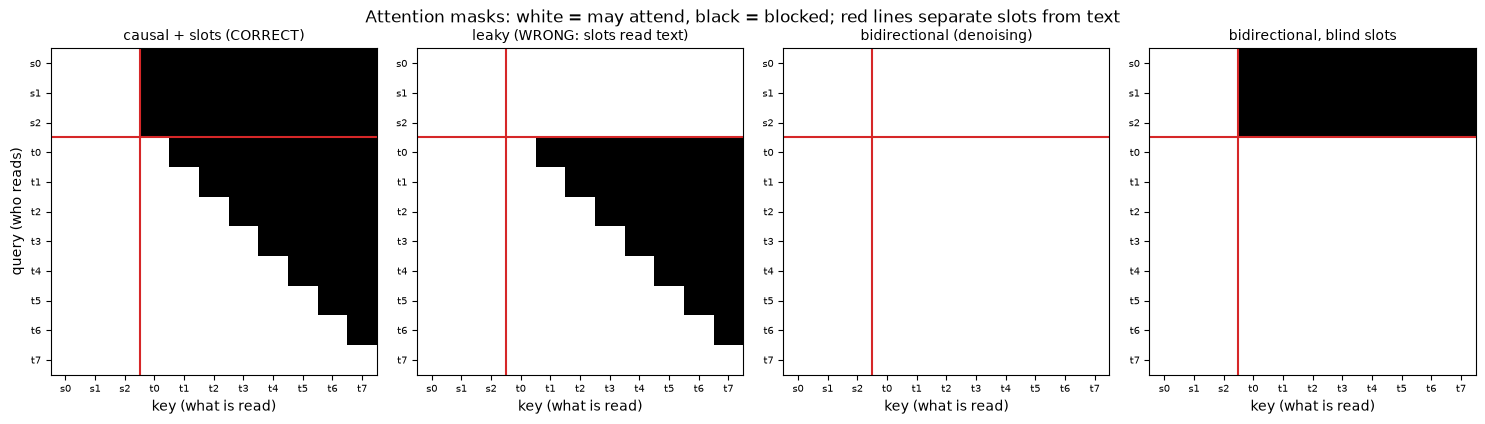

In [4]:
def show_masks(n_mem: int = 3, n_text: int = 8) -> None:
    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    labels = [f"s{i}" for i in range(n_mem)] + [f"t{i}" for i in range(n_text)]
    titles = {"causal": "causal + slots (CORRECT)", "leaky": "leaky (WRONG: slots read text)",
              "bidirectional": "bidirectional (denoising)", "bidirectional_blind": "bidirectional, blind slots"}
    for ax, mode in zip(axes, MASK_MODES):
        allowed = (~build_attention_mask(n_mem, n_text, mode)).float()
        ax.imshow(allowed, cmap="Greys_r", vmin=0, vmax=1)
        ax.axhline(n_mem - 0.5, color="tab:red", lw=1.5)
        ax.axvline(n_mem - 0.5, color="tab:red", lw=1.5)
        ax.set_xticks(range(len(labels)), labels, fontsize=7)
        ax.set_yticks(range(len(labels)), labels, fontsize=7)
        ax.set_title(titles[mode], fontsize=10)
        ax.set_xlabel("key (what is read)")
    axes[0].set_ylabel("query (who reads)")
    fig.suptitle("Attention masks: white = may attend, black = blocked; red lines separate slots from text")
    plt.tight_layout()
    plt.show()


show_masks()

Read the left panel row by row: slot rows `s*` are white only in the slot columns; text row `t5` is white on all slots and on
`t0..t5`. The second panel differs in a single block - the top-right one - and that block is the whole bug.

### 3.2 The shared pre-norm block
The series' reference block: LayerNorm -> causal multi-head self-attention -> residual, LayerNorm -> MLP(GELU) -> residual.
We use `nn.MultiheadAttention`; the mask is passed in, so the same block serves every mode. `need_weights=True` returns the
head-averaged attention matrix, which we use in section 7 to look inside.

In [5]:
class PreNormBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, mlp_mult: int = 4) -> None:
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, mlp_mult * d_model), nn.GELU(),
                                 nn.Linear(mlp_mult * d_model, d_model))

    def forward(self, x: torch.Tensor, blocked: torch.Tensor, need_weights: bool = False):
        """x: (B, S, d); blocked: (S, S) bool, True = may not attend. Returns (x, attn (B, S, S) or None)."""
        h = self.ln1(x)
        attn_out, attn_w = self.attn(h, h, h, attn_mask=blocked, need_weights=need_weights,
                                     average_attn_weights=True)
        x = x + attn_out
        x = x + self.mlp(self.ln2(x))
        return x, attn_w

In [6]:
blk = PreNormBlock(d_model=32, n_heads=4)
toy_x = torch.randn(2, 3 + 5, 32)                    # B=2, M=3 slots + L=5 text, d=32
out, w = blk(toy_x, build_attention_mask(3, 5, "causal"), need_weights=True)
print("out", tuple(out.shape), "| attn", tuple(w.shape))
assert out.shape == toy_x.shape and w.shape == (2, 8, 8)
assert torch.allclose(w.sum(-1), torch.ones(2, 8), atol=1e-5)          # each query's weights sum to 1
assert w[:, :3, 3:].abs().max() == 0                                     # slots put zero weight on text
assert w[:, 3:, 3:].triu(1).abs().max() == 0                             # no text->future-text weight
print("block checks passed")

out (2, 8, 32) | attn (2, 8, 8)
block checks passed


## 4. The full model

`LoopedMemoryLM` = embeddings + learned slot init + **one** shared block applied `n_passes` times + head. Slots are concatenated
in front of the text at every pass, split off after it, and carried to the next pass. With `n_mem=0` it is a plain looped
(Universal-Transformer-style) model, our baseline. `record=True` returns the per-pass attention matrices and slot states.

In [7]:
class LoopedMemoryLM(nn.Module):
    def __init__(self, vocab_size: int, d_model: int = 96, n_heads: int = 4, n_passes: int = 4,
                 n_mem: int = 4, max_len: int = 128, mask_mode: str = "causal") -> None:
        super().__init__()
        assert mask_mode in MASK_MODES
        self.n_mem, self.n_passes, self.mask_mode = n_mem, n_passes, mask_mode
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Parameter(0.02 * torch.randn(max_len, d_model))
        self.pass_emb = nn.Parameter(0.02 * torch.randn(n_passes, d_model))   # tells the block which pass it is in
        self.mem_init = nn.Parameter(0.02 * torch.randn(n_mem, d_model))      # (M, d); M=0 gives an empty tensor
        self.block = PreNormBlock(d_model, n_heads)
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)
        self._mask_cache: dict = {}

    def blocked_mask(self, n_text: int) -> torch.Tensor:
        if n_text not in self._mask_cache:
            self._mask_cache[n_text] = build_attention_mask(self.n_mem, n_text, self.mask_mode)
        return self._mask_cache[n_text]

    def forward(self, idx: torch.Tensor, record: bool = False):
        """idx: (B, L) token ids -> logits (B, L, V), trace dict (filled only if record=True)."""
        batch, n_text = idx.shape
        h = self.tok_emb(idx) + self.pos_emb[:n_text]                  # (B, L, d)
        mem = self.mem_init.unsqueeze(0).expand(batch, -1, -1)          # (B, M, d), same start for every sequence
        blocked = self.blocked_mask(n_text)
        trace = {"attn": [], "mem": [mem.detach()]}
        for t in range(self.n_passes):
            z = torch.cat([mem, h], dim=1) + self.pass_emb[t]           # (B, M+L, d)
            z, attn_w = self.block(z, blocked, need_weights=record)
            mem, h = z[:, :self.n_mem], z[:, self.n_mem:]               # carry slots, keep text
            if record:
                trace["attn"].append(attn_w.detach())
                trace["mem"].append(mem.detach())
        logits = self.head(self.ln_f(h))                                # slots are dropped here
        return logits, trace


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())

In [8]:
m = LoopedMemoryLM(vocab_size=50, d_model=32, n_heads=4, n_passes=3, n_mem=2, max_len=16)
logits, tr = m(torch.randint(0, 50, (2, 10)), record=True)
print("logits", tuple(logits.shape), "| passes recorded", len(tr["attn"]), "| slot states", len(tr["mem"]),
      tuple(tr["mem"][-1].shape))
assert logits.shape == (2, 10, 50)
assert len(tr["attn"]) == 3 and tr["attn"][0].shape == (2, 12, 12)

# Gradient flow: the loss must reach the slot initialisation and the shared block.
loss = logits.logsumexp(-1).mean()
loss.backward()
assert m.mem_init.grad is not None and m.mem_init.grad.abs().sum() > 0, "no gradient into the slots"
assert m.block.attn.in_proj_weight.grad.abs().sum() > 0
print("gradient reaches mem_init: |grad| =", f"{m.mem_init.grad.norm():.2e}")

logits (2, 10, 50) | passes recorded 3 | slot states 4 (2, 2, 32)
gradient reaches mem_init: |grad| = 5.94e-01


### 4.1 The leakage test - and the wrong mask caught red-handed

**The test.** Take a random sequence, change the token at position $j$, run the model on both. For a causal LM, logits at
positions $< j$ must be *bit-for-bit unchanged* (we allow $10^{-5}$ for float noise). We try several $j$. This is the single most
valuable test for any custom mask: it checks the *behaviour*, so it also catches bugs in code paths you forgot about.

In [9]:
def max_future_leak(model: nn.Module, vocab_size: int, n_text: int = 24, n_trials: int = 6, seed: int = 0) -> float:
    """Largest change in logits at positions < j caused by changing the token at position j."""
    gen = torch.Generator().manual_seed(seed)
    model.eval()
    worst = 0.0
    with torch.no_grad():
        for _ in range(n_trials):
            x = torch.randint(0, vocab_size, (2, n_text), generator=gen)
            j = int(torch.randint(1, n_text, (1,), generator=gen))
            x2 = x.clone()
            x2[:, j] = (x[:, j] + 1) % vocab_size          # perturb ONE future token
            a, _ = model(x)
            b, _ = model(x2)
            worst = max(worst, (a[:, :j] - b[:, :j]).abs().max().item())
    return worst


def assert_no_future_leak(model: nn.Module, vocab_size: int, tol: float = 1e-5) -> None:
    leak = max_future_leak(model, vocab_size)
    assert leak < tol, f"future-token leakage detected: earlier logits moved by {leak:.3e}"

In [10]:
set_seed(1)
good = LoopedMemoryLM(vocab_size=40, d_model=32, n_heads=4, n_passes=3, n_mem=4, max_len=32, mask_mode="causal")
set_seed(1)
bad = LoopedMemoryLM(vocab_size=40, d_model=32, n_heads=4, n_passes=3, n_mem=4, max_len=32, mask_mode="leaky")

assert_no_future_leak(good, 40)
print(f"correct mask: max leak = {max_future_leak(good, 40):.2e}  -> PASS")

caught = False
try:
    assert_no_future_leak(bad, 40)
except AssertionError as err:
    caught = True
    print("leaky mask:  ", "CAUGHT ->", err)
assert caught, "the leakage test should have failed for the leaky mask"

correct mask: max leak = 0.00e+00  -> PASS
leaky mask:   CAUGHT -> future-token leakage detected: earlier logits moved by 1.388e-01


**A subtle trap: with one pass the leaky mask passes the test.** In a single block, text tokens read the slots' *input* states
(their learned init); the slots read the text *at the same time*, but what they learn only reaches the text in the *next* pass
(or next layer). So a 1-pass, 1-layer model with the wrong mask is accidentally leak-free, and a unit test written on a
1-layer toy would wrongly certify the mask. **Always run the leakage test with at least 2 passes/layers.**

In [11]:
leak_by_passes = {}
for n_passes in (1, 2, 3):
    set_seed(1)
    probe = LoopedMemoryLM(vocab_size=40, d_model=32, n_heads=4, n_passes=n_passes, n_mem=4, max_len=32,
                           mask_mode="leaky")
    leak_by_passes[n_passes] = max_future_leak(probe, 40)
    print(f"leaky mask, {n_passes} pass(es): max leak = {leak_by_passes[n_passes]:.2e}")
assert leak_by_passes[1] < 1e-5, "1 pass: the leak cannot reach the text yet"
assert leak_by_passes[2] > 1e-3 and leak_by_passes[3] > 1e-3

leaky mask, 1 pass(es): max leak = 0.00e+00
leaky mask, 2 pass(es): max leak = 1.29e-01
leaky mask, 3 pass(es): max leak = 1.39e-01


### 4.2 Causal slots are input-independent

Section 2 claimed that under the correct mask the slot states never depend on the input. Here is the proof by experiment:
two unrelated batches produce identical slot states after every pass. With the leaky mask they differ.

In [12]:
xa = torch.randint(0, 40, (3, 20))
xb = torch.randint(0, 40, (3, 20))
with torch.no_grad():
    mem_a = good(xa, record=True)[1]["mem"]
    mem_b = good(xb, record=True)[1]["mem"]
    leaky_a = bad(xa, record=True)[1]["mem"]
    leaky_b = bad(xb, record=True)[1]["mem"]
for t, (ma, mb) in enumerate(zip(mem_a, mem_b)):
    assert torch.allclose(ma, mb, atol=1e-6), f"pass {t}: causal slots depend on the input!"
    assert torch.allclose(ma[0], ma[1], atol=1e-6)            # also identical across sequences of one batch
diff_leaky = (leaky_a[-1] - leaky_b[-1]).abs().max().item()
print(f"causal slots: identical for every input at all {len(mem_a)} states")
print(f"leaky slots: final states differ by up to {diff_leaky:.3f}")
assert diff_leaky > 1e-3

causal slots: identical for every input at all 4 states
leaky slots: final states differ by up to 1.844


### 4.3 Parameters vs compute

Slots add only $M\cdot d$ parameters but lengthen every attention call from $L$ to $M+L$ positions, at every pass.
A rough forward FLOP count per sequence (multiply-adds x2): linear layers $2\,(M+L)\cdot 12d^2$ and attention
$2\cdot 2\,(M+L)^2 d$ per pass, times $T$, plus the head.

In [13]:
def approx_forward_flops(n_mem: int, n_text: int, d: int, n_passes: int, vocab: int) -> float:
    s = n_mem + n_text
    per_pass = 2 * s * 12 * d * d + 4 * s * s * d
    return n_passes * per_pass + 2 * n_text * d * vocab


D_MODEL, N_HEADS, N_PASSES, SEQ_LEN = 96, 4, 4, 64
VOCAB_PREVIEW = 100
print(f"{'M':>3} | {'params':>8} | {'fwd MFLOP/seq':>13} | {'vs M=0':>6}")
base = approx_forward_flops(0, SEQ_LEN, D_MODEL, N_PASSES, VOCAB_PREVIEW)
for n_mem in (0, 2, 4, 8):
    p = count_params(LoopedMemoryLM(VOCAB_PREVIEW, D_MODEL, N_HEADS, N_PASSES, n_mem, 2 * SEQ_LEN))
    f = approx_forward_flops(n_mem, SEQ_LEN, D_MODEL, N_PASSES, VOCAB_PREVIEW)
    print(f"{n_mem:>3} | {p:>8,} | {f / 1e6:>13.1f} | {f / base:>5.2f}x")

  M |   params | fwd MFLOP/seq | vs M=0
  0 |  144,004 |          64.1 |  1.00x
  2 |  144,196 |          66.3 |  1.03x
  4 |  144,388 |          68.5 |  1.07x
  8 |  144,772 |          72.9 |  1.14x


## 5. Data

Two corpora, as in the whole series: (a) the 4-sentence toy corpus for interpretable pictures, (b) English docstrings from the
Python standard library for honest held-out numbers (90/10 split by position, random 64-character training windows).

In [14]:
TOY_CORPUS = [
    "the tiny model learned to write this sentence :)",
    "the tiny robot learned to write this sentence :)",
    "the tiny model learned to spell this sentence :)",
    "the tiny robot learned to spell this sentence :)",
]  # 48 chars each; two genuine choice points: model/robot and write/spell


def docstring_corpus() -> str:
    """Real English text that ships with Python: docstrings of standard-library modules."""
    import importlib, inspect, re
    mods = ["collections", "itertools", "functools", "json", "re", "string", "textwrap", "pathlib",
            "datetime", "statistics", "random", "heapq", "bisect", "typing", "dataclasses", "argparse",
            "logging", "enum", "fractions", "decimal", "csv", "shutil", "tempfile", "contextlib", "abc",
            "copy", "pprint", "difflib", "calendar", "zipfile"]
    docs = []
    for m in mods:
        for _, obj in inspect.getmembers(importlib.import_module(m)):
            d = inspect.getdoc(obj)
            if d and len(d) > 60 and (inspect.isfunction(obj) or inspect.isclass(obj) or inspect.ismethod(obj)):
                docs.append(d)
    return re.sub(r"\s+", " ", " ".join(dict.fromkeys(docs)))


TEXT = docstring_corpus()
print(f"docstring corpus: {len(TEXT):,} characters")
print(repr(TEXT[:200]))

docstring corpus: 142,997 characters
'A ChainMap groups multiple dicts (or other mappings) together to create a single, updateable view. The underlying mappings are stored in a list. That list is public and can be accessed or updated usin'


In [15]:
class CharTokenizer:
    """Character-level tokenizer plus two special ids: <pause> (section 8.4) and <mask> (section 8.3)."""

    def __init__(self, text: str) -> None:
        self.chars = sorted(set(text))
        self.stoi = {c: i for i, c in enumerate(self.chars)}
        self.n_chars = len(self.chars)
        self.pause_id = self.n_chars
        self.mask_id = self.n_chars + 1
        self.vocab_size = self.n_chars + 2

    def encode(self, s: str) -> list[int]:
        return [self.stoi[c] for c in s]

    def decode(self, ids: list[int]) -> str:
        specials = {self.pause_id: "|", self.mask_id: "_"}
        return "".join(specials.get(i, self.chars[i] if i < self.n_chars else "?") for i in ids)


tok = CharTokenizer(TEXT + "".join(TOY_CORPUS))
data = torch.tensor(tok.encode(TEXT), dtype=torch.long)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]
print(f"vocab: {tok.n_chars} characters + 2 specials = {tok.vocab_size} | train {len(train_data):,} | val {len(val_data):,}")
print(f"uniform guess = log2({tok.n_chars}) = {math.log2(tok.n_chars):.2f} bits/char")
assert tok.decode(tok.encode(TEXT[:500])) == TEXT[:500]
toy_ids = torch.tensor([tok.encode(s) for s in TOY_CORPUS])
assert toy_ids.shape == (4, 48)

vocab: 98 characters + 2 specials = 100 | train 128,697 | val 14,300
uniform guess = log2(98) = 6.61 bits/char


In [16]:
SEQ_LEN, BATCH = 64, 32


def get_batch(source: torch.Tensor, batch: int, seq_len: int, gen: torch.Generator):
    """Random windows: x = chars [i, i+L), y = chars [i+1, i+L+1)."""
    starts = torch.randint(0, len(source) - seq_len - 1, (batch,), generator=gen)
    x = torch.stack([source[s:s + seq_len] for s in starts])
    y = torch.stack([source[s + 1:s + seq_len + 1] for s in starts])
    return x, y


def val_windows(source: torch.Tensor, seq_len: int, max_windows: int = 400):
    """Deterministic, non-overlapping validation windows."""
    n = min(max_windows, (len(source) - 1) // seq_len)
    x = torch.stack([source[i * seq_len:(i + 1) * seq_len] for i in range(n)])
    y = torch.stack([source[i * seq_len + 1:(i + 1) * seq_len + 1] for i in range(n)])
    return x, y


VAL_X, VAL_Y = val_windows(val_data, SEQ_LEN)
xb_, yb_ = get_batch(train_data, 4, SEQ_LEN, torch.Generator().manual_seed(0))
assert torch.equal(xb_[:, 1:], yb_[:, :-1])          # y is x shifted by one
print("val windows:", tuple(VAL_X.shape), "=", VAL_X.numel(), "scored characters")

val windows: (223, 64) = 14272 scored characters


## 6. Training loop

Written out explicitly: AdamW, linear warm-up then cosine decay, gradient clipping. The loss function is passed in so the same
loop trains the causal LM, the pause-token model and the masked denoiser. Bits/char = cross-entropy (nats) / ln 2; we check
that against a hand-written $-\log_2 p$.

In [17]:
def lm_loss(model: nn.Module, x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    logits, _ = model(x)
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))


def lr_at(step: int, total: int, peak: float, warmup: int = 50) -> float:
    if step < warmup:
        return peak * (step + 1) / warmup
    progress = (step - warmup) / max(1, total - warmup)
    return peak * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress)))


def train(model: nn.Module, loss_fn, batch_fn, steps: int, lr: float = 3e-3, seed: int = 0) -> dict:
    gen = torch.Generator().manual_seed(seed)          # same batches for every model with the same seed
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01, betas=(0.9, 0.95))
    losses = []
    model.train()
    t0 = time.time()
    for step in range(steps):
        for group in opt.param_groups:
            group["lr"] = lr_at(step, steps, lr)
        x, y = batch_fn(gen)
        loss = loss_fn(model, x, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        losses.append(loss.item())
    seconds = time.time() - t0
    return {"losses": losses, "seconds": seconds, "ms_per_step": 1000 * seconds / steps}


@torch.no_grad()
def eval_bpc(model: nn.Module, x: torch.Tensor, y: torch.Tensor, loss_fn=lm_loss, chunk: int = 100) -> float:
    model.eval()
    total, count = 0.0, 0
    for i in range(0, len(x), chunk):
        xb, yb = x[i:i + chunk], y[i:i + chunk]
        total += loss_fn(model, xb, yb).item() * yb.numel()
        count += yb.numel()
    model.train()
    return total / count / math.log(2)


def train_batch_fn(gen: torch.Generator):
    return get_batch(train_data, BATCH, SEQ_LEN, gen)

In [18]:
# bpc two ways on an untrained model: F.cross_entropy / ln2  vs  mean of -log2 softmax at the target.
set_seed(0)
probe = LoopedMemoryLM(tok.vocab_size, 64, 4, 2, 2, 128)
probe.eval()
with torch.no_grad():
    logits, _ = probe(VAL_X[:8])
    manual = -(torch.log_softmax(logits, -1).gather(-1, VAL_Y[:8, :, None]) / math.log(2)).mean().item()
via_ce = eval_bpc(probe, VAL_X[:8], VAL_Y[:8])
print(f"untrained bpc: cross-entropy route {via_ce:.5f} | manual route {manual:.5f} | log2(V) = {math.log2(tok.vocab_size):.3f}")
assert abs(manual - via_ce) < 1e-4

untrained bpc: cross-entropy route 7.03769 | manual route 7.03769 | log2(V) = 6.644


### 6.1 First training run: toy corpus, M = 4 slots
A tiny run on the four toy sentences so that we have an interpretable model to look inside (section 7). The input is the
first 47 characters, the target the last 47.

In [19]:
TOY_X, TOY_Y = toy_ids[:, :-1], toy_ids[:, 1:]


def toy_batch_fn(gen: torch.Generator):
    rows = torch.randint(0, 4, (16,), generator=gen)
    return TOY_X[rows], TOY_Y[rows]


set_seed(0)
toy_model = LoopedMemoryLM(tok.vocab_size, d_model=64, n_heads=4, n_passes=4, n_mem=4, max_len=64)
toy_run = train(toy_model, lm_loss, toy_batch_fn, steps=300, lr=3e-3)
toy_bits = eval_bpc(toy_model, TOY_X, TOY_Y)
# Ideal: 2 binary choices per sentence over 47 predictions -> 2 bits / 47 chars.
print(f"toy: {toy_run['seconds']:.1f}s, final train loss {toy_run['losses'][-1]:.3f} nats, "
      f"{toy_bits:.4f} bits/char (ideal {2 / 47:.4f})")
assert_no_future_leak(toy_model, tok.vocab_size)       # the trained model is still causal

with torch.no_grad():
    probs = torch.softmax(toy_model(TOY_X[:1])[0][0], -1)
for prefix, a, b in (("the tiny ", "m", "r"), ("the tiny model learned to ", "w", "s")):
    pos = len(prefix) - 1            # logits at the last prefix char predict the next char
    print(f"after {prefix!r}: p({a})={probs[pos, tok.stoi[a]]:.2f}  p({b})={probs[pos, tok.stoi[b]]:.2f}")

toy: 6.9s, final train loss 0.032 nats, 0.0439 bits/char (ideal 0.0426)
after 'the tiny ': p(m)=0.60  p(r)=0.39
after 'the tiny model learned to ': p(w)=0.51  p(s)=0.49


### 6.2 Main runs: looped LM with M = 0, 2, 4, 8 slots on docstrings

Matched settings: $d=96$, 4 heads, one shared block looped $T=4$ times, batch 32 x 64 chars, 800 AdamW steps at peak lr
$3\cdot10^{-3}$, identical batches (same data seed) for every $M$. Two model-init seeds per $M$ to see run-to-run noise.

In [20]:
STEPS = 800
SEEDS = (0, 1)
SLOT_COUNTS = (0, 2, 4, 8)
results = {}            # (n_mem, seed) -> dict
models = {}
for n_mem in SLOT_COUNTS:
    for seed in SEEDS:
        set_seed(seed)
        model = LoopedMemoryLM(tok.vocab_size, D_MODEL, N_HEADS, N_PASSES, n_mem, max_len=2 * SEQ_LEN)
        run = train(model, lm_loss, train_batch_fn, STEPS, seed=100)       # data seed fixed across runs
        run["val_bpc"] = eval_bpc(model, VAL_X, VAL_Y)
        run["params"] = count_params(model)
        results[(n_mem, seed)] = run
        models[(n_mem, seed)] = model
        print(f"M={n_mem} seed={seed}: val {run['val_bpc']:.4f} bpc | {run['params']:,} params | "
              f"{run['ms_per_step']:.1f} ms/step | {run['seconds']:.1f}s")

M=0 seed=0: val 3.2299 bpc | 144,004 params | 60.4 ms/step | 48.3s


M=0 seed=1: val 3.1822 bpc | 144,004 params | 54.9 ms/step | 43.9s


M=2 seed=0: val 3.2013 bpc | 144,196 params | 70.4 ms/step | 56.3s


M=2 seed=1: val 3.1884 bpc | 144,196 params | 93.9 ms/step | 75.1s


M=4 seed=0: val 3.1549 bpc | 144,388 params | 134.7 ms/step | 107.8s


M=4 seed=1: val 3.1783 bpc | 144,388 params | 160.2 ms/step | 128.1s


M=8 seed=0: val 3.1606 bpc | 144,772 params | 62.8 ms/step | 50.2s


M=8 seed=1: val 3.1734 bpc | 144,772 params | 1667.7 ms/step | 1334.2s


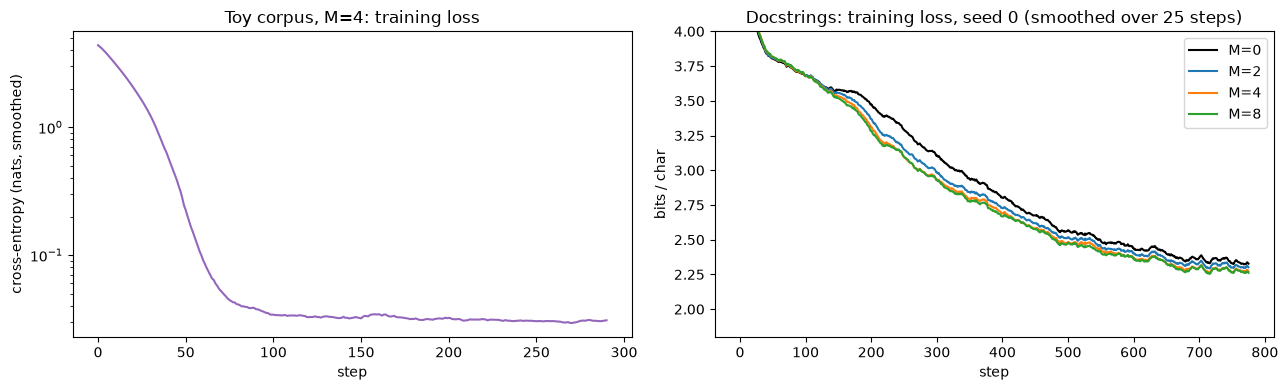

In [21]:
def smooth(values: list[float], k: int = 25) -> np.ndarray:
    v = np.asarray(values)
    return np.convolve(v, np.ones(k) / k, mode="valid")


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(smooth(toy_run["losses"], 10), color="tab:purple")
axes[0].set_title("Toy corpus, M=4: training loss")
axes[0].set_xlabel("step")
axes[0].set_ylabel("cross-entropy (nats, smoothed)")
axes[0].set_yscale("log")
colors = {0: "black", 2: "tab:blue", 4: "tab:orange", 8: "tab:green"}
for n_mem in SLOT_COUNTS:
    axes[1].plot(smooth(results[(n_mem, 0)]["losses"]) / math.log(2), color=colors[n_mem], label=f"M={n_mem}")
axes[1].set_title("Docstrings: training loss, seed 0 (smoothed over 25 steps)")
axes[1].set_xlabel("step")
axes[1].set_ylabel("bits / char")
axes[1].set_ylim(1.8, 4.0)
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Look inside

### 7.1 How much do text tokens attend to the slots, per pass? (toy model)
For one toy sentence we take the head-averaged attention of each text position (columns, labelled by the character at that
position) to each slot (rows), one panel per pass.

pass 0: mean attention mass on all slots = 0.169
pass 1: mean attention mass on all slots = 0.135
pass 2: mean attention mass on all slots = 0.149
pass 3: mean attention mass on all slots = 0.147


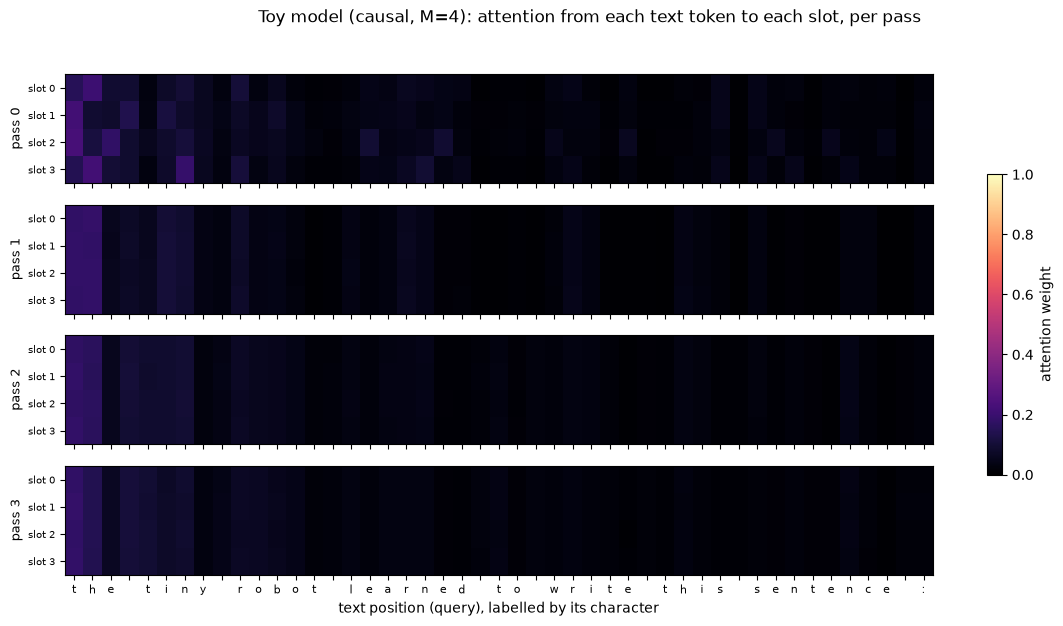

In [22]:
with torch.no_grad():
    _, toy_trace = toy_model(TOY_X[1:2], record=True)          # "the tiny robot learned to write ..."
n_mem_toy = toy_model.n_mem
chars = list(TOY_CORPUS[1][:-1])
fig, axes = plt.subplots(N_PASSES, 1, figsize=(14, 6.5), sharex=True)
for t, ax in enumerate(axes):
    text_to_slot = toy_trace["attn"][t][0, n_mem_toy:, :n_mem_toy].T       # (M, L)
    im = ax.imshow(text_to_slot, aspect="auto", cmap="magma", vmin=0, vmax=1)
    ax.set_yticks(range(n_mem_toy), [f"slot {i}" for i in range(n_mem_toy)], fontsize=7)
    ax.set_ylabel(f"pass {t}", fontsize=9)
    print(f"pass {t}: mean attention mass on all slots = {text_to_slot.sum(0).mean():.3f}")
axes[-1].set_xticks(range(len(chars)), chars, fontsize=8)
axes[-1].set_xlabel("text position (query), labelled by its character")
fig.colorbar(im, ax=axes, shrink=0.6, label="attention weight")
fig.suptitle("Toy model (causal, M=4): attention from each text token to each slot, per pass")
plt.show()

### 7.2 What happens to the slot states across passes?
Slot norms per pass, and the cosine similarity between every (pass, slot) state. Under the causal mask these are the same for
every input (asserted in 4.2), so a single picture describes the slots completely.

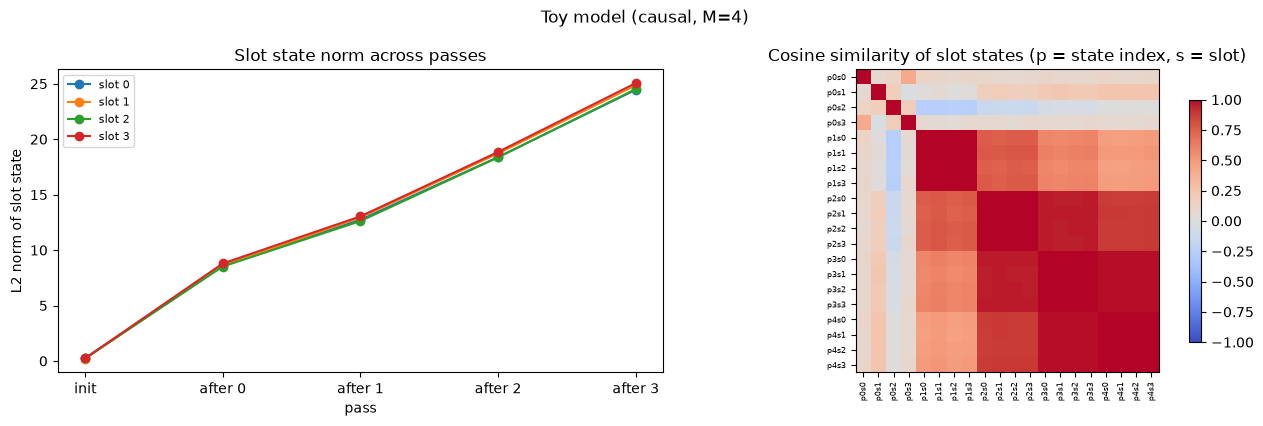

mean cosine(slot state, same slot one pass later): ['-0.00', '0.77', '0.96', '0.98']


In [23]:
def slot_state_plots(trace: dict, title: str) -> None:
    states = torch.stack([s[0] for s in trace["mem"]])           # (T+1, M, d), batch element 0
    n_states, n_mem, _ = states.shape
    norms = states.norm(dim=-1)                                   # (T+1, M)
    flat = F.normalize(states.reshape(n_states * n_mem, -1), dim=-1)
    cos = flat @ flat.T
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
    for s in range(n_mem):
        axes[0].plot(range(n_states), norms[:, s], marker="o", label=f"slot {s}")
    axes[0].set_xticks(range(n_states), ["init"] + [f"after {t}" for t in range(n_states - 1)])
    axes[0].set_xlabel("pass")
    axes[0].set_ylabel("L2 norm of slot state")
    axes[0].set_title("Slot state norm across passes")
    axes[0].legend(fontsize=8)
    im = axes[1].imshow(cos, cmap="coolwarm", vmin=-1, vmax=1)
    ticks = [f"p{t}s{s}" for t in range(n_states) for s in range(n_mem)]
    axes[1].set_xticks(range(len(ticks)), ticks, rotation=90, fontsize=6)
    axes[1].set_yticks(range(len(ticks)), ticks, fontsize=6)
    axes[1].set_title("Cosine similarity of slot states (p = state index, s = slot)")
    fig.colorbar(im, ax=axes[1], shrink=0.8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    adjacent = [F.cosine_similarity(states[t], states[t + 1], dim=-1).mean().item() for t in range(n_states - 1)]
    print("mean cosine(slot state, same slot one pass later):", [f"{a:.2f}" for a in adjacent])


slot_state_plots(toy_trace, "Toy model (causal, M=4)")

### 7.3 Attention mass on slots in the docstring models
Averaged over 100 validation windows and all text positions: the fraction of each text token's attention that goes to slots,
per pass. A uniform reader would give $M/(M+i)$ at position $i$; we print that for comparison.

In [24]:
slot_mass = {}
with torch.no_grad():
    for n_mem in (2, 4, 8):
        mdl = models[(n_mem, 0)]
        mdl.eval()
        _, tr = mdl(VAL_X[:100], record=True)
        per_pass = [a[:, n_mem:, :n_mem].sum(-1).mean().item() for a in tr["attn"]]
        uniform = np.mean([n_mem / (n_mem + i + 1) for i in range(SEQ_LEN)])
        slot_mass[n_mem] = per_pass
        print(f"M={n_mem}: attention mass on slots per pass = {[f'{p:.3f}' for p in per_pass]} "
              f"(uniform reader would give {uniform:.3f})")
        mdl.train()

M=2: attention mass on slots per pass = ['0.188', '0.022', '0.027', '0.027'] (uniform reader would give 0.102)
M=4: attention mass on slots per pass = ['0.225', '0.024', '0.033', '0.040'] (uniform reader would give 0.170)
M=8: attention mass on slots per pass = ['0.257', '0.023', '0.035', '0.039'] (uniform reader would give 0.268)


## 8. Experiments

### 8.1 Do memory slots help a causal looped LM? (results of 6.2)

In [25]:
print(f"{'M':>3} | {'val bpc (seed 0, 1)':>22} | {'mean':>7} | {'params':>8} | {'ms/step':>7} | {'train s':>7}")
summary = {}
for n_mem in SLOT_COUNTS:
    bpcs = [results[(n_mem, s)]["val_bpc"] for s in SEEDS]
    ms = np.mean([results[(n_mem, s)]["ms_per_step"] for s in SEEDS])
    secs = np.mean([results[(n_mem, s)]["seconds"] for s in SEEDS])
    summary[n_mem] = float(np.mean(bpcs))
    print(f"{n_mem:>3} | {bpcs[0]:>10.4f}, {bpcs[1]:>9.4f} | {np.mean(bpcs):>7.4f} | "
          f"{results[(n_mem, 0)]['params']:>8,} | {ms:>7.1f} | {secs:>7.1f}")
seed_spread = np.mean([abs(results[(m_, 0)]["val_bpc"] - results[(m_, 1)]["val_bpc"]) for m_ in SLOT_COUNTS])
print(f"\nmean |seed0 - seed1| gap = {seed_spread:.4f} bpc  (differences smaller than this are noise)")
print(f"best M - M=0: {min(summary.values()) - summary[0]:+.4f} bpc")
for n_mem in (2, 4, 8):                                        # every trained causal model is leak-free
    assert_no_future_leak(models[(n_mem, 0)], tok.vocab_size)

  M |    val bpc (seed 0, 1) |    mean |   params | ms/step | train s
  0 |     3.2299,    3.1822 |  3.2060 |  144,004 |    57.7 |    46.1
  2 |     3.2013,    3.1884 |  3.1948 |  144,196 |    82.1 |    65.7
  4 |     3.1549,    3.1783 |  3.1666 |  144,388 |   147.4 |   118.0
  8 |     3.1606,    3.1734 |  3.1670 |  144,772 |   865.2 |   692.2

mean |seed0 - seed1| gap = 0.0242 bpc  (differences smaller than this are noise)
best M - M=0: -0.0394 bpc


RESULT_8_1

### 8.2 The wrong mask, trained: a result that is too good to be true

Same settings, $M=4$, but the `leaky` mask. If validation bits/char comes out clearly *better* than every honest model, that is
not a breakthrough - it is the model reading the answer through the slots. The number is meaningless as a language-model score,
which is exactly why the leakage test must run before any number is reported.

In [26]:
set_seed(0)
leaky_model = LoopedMemoryLM(tok.vocab_size, D_MODEL, N_HEADS, N_PASSES, 4, max_len=2 * SEQ_LEN, mask_mode="leaky")
leaky_run = train(leaky_model, lm_loss, train_batch_fn, STEPS, seed=100)
leaky_bpc = eval_bpc(leaky_model, VAL_X, VAL_Y)
print(f"LEAKY M=4: val {leaky_bpc:.4f} bpc vs honest M=4 {summary[4]:.4f} and M=0 {summary[0]:.4f}")
print(f"leakage test on the trained leaky model: max leak = {max_future_leak(leaky_model, tok.vocab_size):.3f}")
assert max_future_leak(leaky_model, tok.vocab_size) > 1e-3

LEAKY M=4: val 2.7186 bpc vs honest M=4 3.1666 and M=0 3.2060
leakage test on the trained leaky model: max leak = 2.715


RESULT_8_2

### 8.3 Bidirectional setting: masked-character denoising, where slots may read text

Task: replace 25% of the characters of a 64-character window with `<mask>` and predict the originals (loss only on masked
positions; we report bits per *masked* character). There is no future to hide, so text reads all text. Three models at matched
settings: no slots; 4 **blind** slots (`bidirectional_blind`: slots read only slots, like the causal rule); 4 **reading** slots
(`bidirectional`: slots read everything). The comparison blind vs reading isolates the value of letting slots read.

In [27]:
MASK_RATE = 0.25


def corrupt(x: torch.Tensor, gen: torch.Generator):
    is_masked = torch.rand(x.shape, generator=gen) < MASK_RATE
    is_masked[:, 0] |= ~is_masked.any(dim=1)               # at least one masked char per row
    return torch.where(is_masked, torch.full_like(x, tok.mask_id), x), is_masked


def denoise_loss(model: nn.Module, x_in: torch.Tensor, packed: torch.Tensor) -> torch.Tensor:
    """packed = (original chars, mask flags) stacked on dim 0 so the generic loop can pass (x, y)."""
    target, is_masked = packed[0], packed[1].bool()
    logits, _ = model(x_in)
    return F.cross_entropy(logits[is_masked], target[is_masked])


def denoise_batch_fn(gen: torch.Generator):
    x, _ = get_batch(train_data, BATCH, SEQ_LEN, gen)
    x_in, is_masked = corrupt(x, gen)
    return x_in, torch.stack([x, is_masked.long()])


# Fixed validation corruption so all models see the same holes.
_vgen = torch.Generator().manual_seed(7)
VAL_DN_IN, VAL_DN_MASK = corrupt(VAL_X, _vgen)


@torch.no_grad()
def eval_denoise_bits(model: nn.Module) -> float:
    model.eval()
    total, count = 0.0, 0
    for i in range(0, len(VAL_X), 100):
        logits, _ = model(VAL_DN_IN[i:i + 100])
        m_ = VAL_DN_MASK[i:i + 100]
        total += F.cross_entropy(logits[m_], VAL_X[i:i + 100][m_], reduction="sum").item()
        count += int(m_.sum())
    model.train()
    return total / count / math.log(2)


x_demo, packed_demo = denoise_batch_fn(torch.Generator().manual_seed(0))
print("corrupted:", tok.decode(x_demo[0].tolist()))
print("original :", tok.decode(packed_demo[0][0].tolist()))
assert packed_demo.shape == (2, BATCH, SEQ_LEN)

corrupted: _ ___ the_f___ is to be_o___ed_ Accept_ the s_m__va_ues a_ the__
original : g how the file is to be opened. Accepts the same values as the b


In [28]:
DENOISE_STEPS = 600
denoise_results = {}
denoise_models = {}
for name, n_mem, mode in (("no slots", 0, "bidirectional"), ("4 blind slots", 4, "bidirectional_blind"),
                          ("4 reading slots", 4, "bidirectional")):
    set_seed(0)
    mdl = LoopedMemoryLM(tok.vocab_size, D_MODEL, N_HEADS, N_PASSES, n_mem, max_len=2 * SEQ_LEN, mask_mode=mode)
    run = train(mdl, denoise_loss, denoise_batch_fn, DENOISE_STEPS, seed=200)
    run["val_bits"] = eval_denoise_bits(mdl)
    denoise_results[name], denoise_models[name] = run, mdl
    print(f"{name:>16}: {run['val_bits']:.4f} bits/masked char | {run['ms_per_step']:.1f} ms/step")

# In the bidirectional model the slots really do depend on the input now.
rd = denoise_models["4 reading slots"]
with torch.no_grad():
    s1 = rd(VAL_DN_IN[:2], record=True)[1]["mem"][-1]
assert (s1[0] - s1[1]).abs().max() > 1e-3, "reading slots should differ between sequences"

        no slots: 4.7617 bits/masked char | 20.3 ms/step


   4 blind slots: 4.7708 bits/masked char | 22.7 ms/step


 4 reading slots: 4.7641 bits/masked char | 22.7 ms/step


pass 0: slots put 0.01 of their attention on slots, 0.99 on text
pass 1: slots put 0.01 of their attention on slots, 0.99 on text
pass 2: slots put 0.02 of their attention on slots, 0.98 on text
pass 3: slots put 0.02 of their attention on slots, 0.98 on text


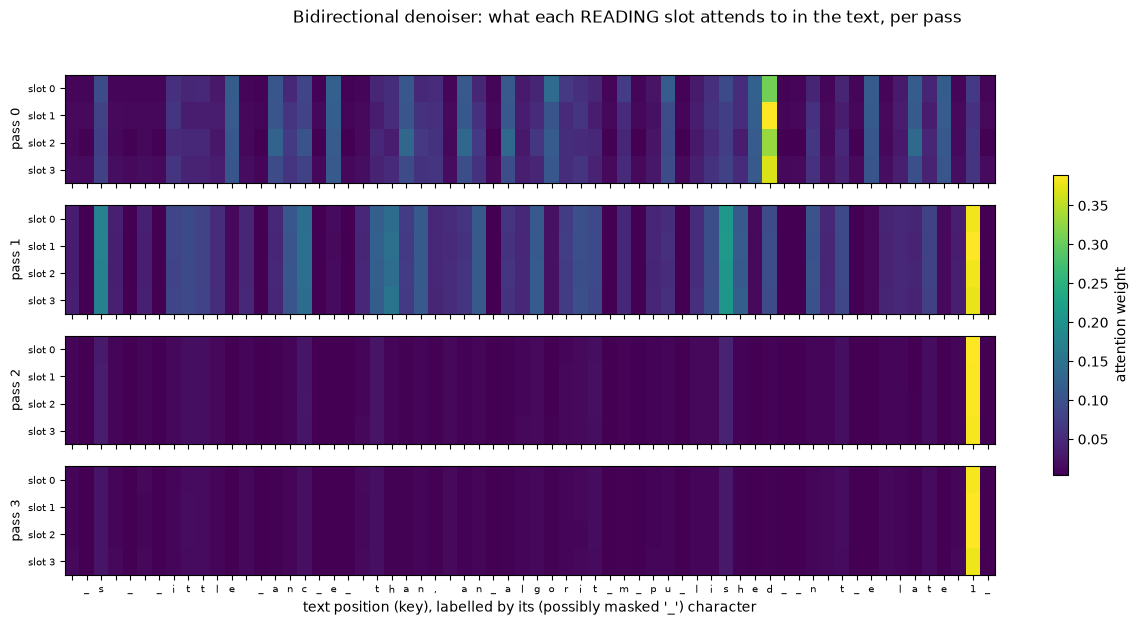

In [29]:
with torch.no_grad():
    _, rd_trace = rd(VAL_DN_IN[:1], record=True)
snippet = tok.decode(VAL_DN_IN[0].tolist())
fig, axes = plt.subplots(N_PASSES, 1, figsize=(15, 6.5), sharex=True)
for t, ax in enumerate(axes):
    slot_reads = rd_trace["attn"][t][0, :4, 4:]                    # (M, L): what each slot reads
    im = ax.imshow(slot_reads, aspect="auto", cmap="viridis")
    ax.set_yticks(range(4), [f"slot {i}" for i in range(4)], fontsize=7)
    ax.set_ylabel(f"pass {t}", fontsize=9)
    own = rd_trace["attn"][t][0, :4, :4].sum(-1).mean().item()
    print(f"pass {t}: slots put {own:.2f} of their attention on slots, {1 - own:.2f} on text")
axes[-1].set_xticks(range(len(snippet)), list(snippet), fontsize=7)
axes[-1].set_xlabel("text position (key), labelled by its (possibly masked '_') character")
fig.colorbar(im, ax=axes, shrink=0.6, label="attention weight")
fig.suptitle("Bidirectional denoiser: what each READING slot attends to in the text, per pass")
plt.show()

RESULT_8_3

### 8.4 Pause tokens in the sequence (vs slots in the loop)

A small pause-token baseline: after every character we insert one `<pause>` token, giving `[c0, P, c1, P, ...]` (length
$2L$). The prediction of $c_{i+1}$ is read from the pause token *after* $c_i$, so each prediction gets one extra position of
computation that can read $c_0..c_i$ (unlike a causal slot, which can read no text). Same looped model, $M=0$, same mask rule
(plain causal over the longer sequence), same steps. Note this is a much denser use of pauses than Goyal et al., who put a
handful of pauses before an answer and also pretrain with them.

In [30]:
def interleave_pauses(x: torch.Tensor) -> torch.Tensor:
    """(B, L) -> (B, 2L): c0 P c1 P ... ; position 2i+1 is the pause after c_i."""
    pauses = torch.full_like(x, tok.pause_id)
    return torch.stack([x, pauses], dim=2).reshape(x.size(0), -1)


def pause_loss(model: nn.Module, x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    logits, _ = model(interleave_pauses(x))
    logits = logits[:, 1::2]                         # read predictions from the pause positions
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))


demo = interleave_pauses(VAL_X[:1, :8])
print(tok.decode(demo[0].tolist()))
assert demo.shape == (1, 16) and torch.equal(demo[0, ::2], VAL_X[0, :8])

set_seed(0)
pause_model = LoopedMemoryLM(tok.vocab_size, D_MODEL, N_HEADS, N_PASSES, 0, max_len=2 * SEQ_LEN)
pause_run = train(pause_model, pause_loss, train_batch_fn, STEPS, seed=100)
pause_bpc = eval_bpc(pause_model, VAL_X, VAL_Y, loss_fn=pause_loss)
assert_no_future_leak(pause_model, tok.vocab_size)
print(f"pause tokens (M=0): val {pause_bpc:.4f} bpc | {pause_run['ms_per_step']:.1f} ms/step "
      f"vs plain M=0 seed 0: {results[(0, 0)]['val_bpc']:.4f} bpc | {results[(0, 0)]['ms_per_step']:.1f} ms/step")

 |i|s| |a| |l|i|


pause tokens (M=0): val 3.1441 bpc | 45.9 ms/step vs plain M=0 seed 0: 3.2299 bpc | 60.4 ms/step


### 8.5 All results in one table

setting                                    |   value | unit             |   params | ms/step
causal LM, M=0 (mean of 2 seeds)           |  3.2060 | bits/char        |  144,004 |    57.7
causal LM, M=2 (mean of 2 seeds)           |  3.1948 | bits/char        |  144,196 |    82.1
causal LM, M=4 (mean of 2 seeds)           |  3.1666 | bits/char        |  144,388 |   147.4
causal LM, M=8 (mean of 2 seeds)           |  3.1670 | bits/char        |  144,772 |   865.2
causal LM + 1 pause per char, M=0          |  3.1441 | bits/char        |  144,004 |    45.9
LEAKY mask, M=4 (invalid: cheats)          |  2.7186 | bits/char        |  144,388 |    35.0
denoise 25%, no slots                      |  4.7617 | bits/masked char |  144,004 |    20.3
denoise 25%, 4 blind slots                 |  4.7708 | bits/masked char |  144,388 |    22.7
denoise 25%, 4 reading slots               |  4.7641 | bits/masked char |  144,388 |    22.7


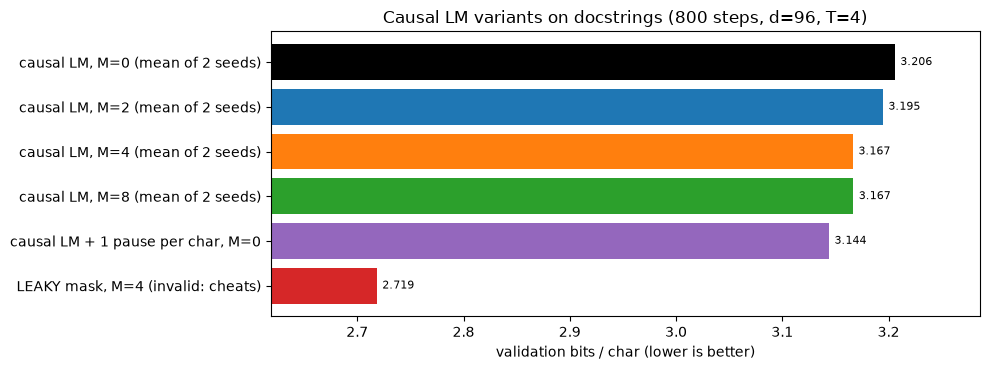

In [31]:
rows = []
for n_mem in SLOT_COUNTS:
    rows.append((f"causal LM, M={n_mem} (mean of 2 seeds)", summary[n_mem], results[(n_mem, 0)]["params"],
                 np.mean([results[(n_mem, s)]["ms_per_step"] for s in SEEDS]), "bits/char"))
rows.append(("causal LM + 1 pause per char, M=0", pause_bpc, count_params(pause_model), pause_run["ms_per_step"],
             "bits/char"))
rows.append(("LEAKY mask, M=4 (invalid: cheats)", leaky_bpc, count_params(leaky_model), leaky_run["ms_per_step"],
             "bits/char"))
for name, run in denoise_results.items():
    rows.append((f"denoise 25%, {name}", run["val_bits"], count_params(denoise_models[name]), run["ms_per_step"],
                 "bits/masked char"))
print(f"{'setting':<42} | {'value':>7} | {'unit':<16} | {'params':>8} | {'ms/step':>7}")
for name, val, params, ms, unit in rows:
    print(f"{name:<42} | {val:>7.4f} | {unit:<16} | {params:>8,} | {ms:>7.1f}")

fig, ax = plt.subplots(figsize=(10, 3.8))
lm_rows = rows[:6]
ax.barh([r[0] for r in lm_rows], [r[1] for r in lm_rows],
        color=["black", "tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:red"])
for i, r in enumerate(lm_rows):
    ax.text(r[1] + 0.005, i, f"{r[1]:.3f}", va="center", fontsize=8)
ax.set_xlim(min(r[1] for r in lm_rows) - 0.1, max(r[1] for r in lm_rows) + 0.08)
ax.invert_yaxis()
ax.set_xlabel("validation bits / char (lower is better)")
ax.set_title("Causal LM variants on docstrings (800 steps, d=96, T=4)")
plt.tight_layout()
plt.show()

## 9. Common pitfalls & debugging tips

PITFALLS

## 10. Recap

RECAP

### Cheat sheet

| Setting | Slots read text? | Slot state depends on input? | Typical use |
|---|---|---|---|
| Causal LM, slots in the loop | **No** (would leak the future) | No - learned constants per pass | attention sink / persistent memory |
| Causal LM, leaky mask | Yes | Yes | **never** - it cheats |
| Bidirectional (denoising, ViT registers) | Yes | Yes | global summary / scratch |
| Pause tokens in the sequence | they are text: read the past | yes (causally) | extra positions before answering |
| Segment-level memory (RMT-style) | read the *previous* segment | yes, without leaking | long context, recurrence over chunks |

```python
blocked = build_attention_mask(n_mem, n_text, "causal")   # True = blocked
z = torch.cat([mem, h], 1) + pass_emb[t]                    # every pass
z, _ = block(z, blocked);  mem, h = z[:, :n_mem], z[:, n_mem:]
assert_no_future_leak(model, vocab)                         # with >= 2 passes!
```

### Exercises

1. **Legal reading slots for a causal LM.** Split each 64-char window into two 32-char chunks. Let the slots read the whole
   *first* chunk (bidirectionally) and then be read by the second chunk, as in the Recurrent Memory Transformer.
   *Hint:* only score the second chunk, extend `may_attend` with a `chunk_id`, and keep `assert_no_future_leak` for positions in
   chunk 2. Compare against M=0 that simply sees both chunks causally.
2. **Replace slots by a constant.** Because causal slots are input-independent, you can run the slot trajectory once, cache
   the per-pass slot keys/values, and delete the slot queries entirely. Implement it and assert identical logits.
   *Hint:* record `trace["mem"]` with batch size 1; at pass $t$ concatenate the cached $m^{(t)}$ but only keep the text rows.
3. **Find the leak with a single pass.** Section 4.1 showed that the leaky mask passes the leakage test with 1 pass. Change the
   model so one pass has *two* blocks (attention twice) and confirm the test now fails with $T=1$.
   *Hint:* the leak needs one step to write the slot and a later step to read it.

### References
* Burtsev, Kuratov, Peganov, Sapunov - *Memory Transformer*, arXiv:2006.11527.
* Darcet, Oquab, Mairal, Bojanowski - *Vision Transformers Need Registers*, arXiv:2309.16588.
* Goyal, Ji, Rawat, Menon, Kumar, Nagarajan - *Think before you speak: Training Language Models With Pause Tokens*, arXiv:2310.02226.
* Dehghani, Gouws, Vinyals, Uszkoreit, Kaiser - *Universal Transformers*, arXiv:1807.03819.
* Sukhbaatar, Grave, Lample, Jegou, Joulin - *Augmenting Self-attention with Persistent Memory*, arXiv:1907.01470.
* Bulatov, Kuratov, Burtsev - *Recurrent Memory Transformer*, arXiv:2207.06881.
* Xiao, Tian, Chen, Han, Lewis - *Efficient Streaming Language Models with Attention Sinks*, arXiv:2309.17453.

In [32]:
print(f"total notebook runtime: {(time.time() - NB_START) / 60:.1f} min")

total notebook runtime: 32.7 min
